# Лабораторная работа №2
## Морфологический анализ, частеречная разметка (POS-tagging) и извлечение синтаксических структур

Датасет: IMDB Dataset of 50K Movie Reviews (Kaggle), колонки `review` (сырой текст рецензии на
английском) и `sentiment` (positive/negative). Тексты англоязычные, поэтому для п.4 выбран
вариант «отзывы» (пары существительное-аспект + прилагательное-оценка), а в п.6 местоимения
он/она/они/это соответствуют английским he/him, she/her, they/them, it.

**Цель:** извлечь морфологические признаки и синтаксические связи из отзывов, сравнить
грамматику классов тональности и реализовать интерпретируемые правила извлечения пар и анафоры.
Используется тот же датасет, что и в Лабораторной работе №1. Разбиение Train/Test здесь
не применяется: готовая модель не дообучается, а задание требует описания всего корпуса.
Проверочные примеры служат локальному анализу правил, а не оценке обучаемого классификатора.

### Содержание
0. Настройка окружения
1. Частеречная разметка корпуса
2. Распределение частей речи и ошибки тэггера
3. Деревья зависимостей
4. Извлечение пар аспект-оценка
5. Анализ топ-20 пар
6. Разрешение анафоры
7. Заключение

### Шаг 0. Настройка окружения

In [1]:
import html
import hashlib
import json
import pickle
import random
import re
import sys
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
import spacy
from IPython.display import SVG, display
from spacy import displacy
from spacy.tokens import DocBin

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# датасет лежит в data/ (лаба в корне репозитория) или в ../data/ (лаба в подпапке)
DATA_PATH = next(p for p in (Path("data"), Path("../data")) if (p / "IMDB Dataset.csv").exists()) / "IMDB Dataset.csv"
CACHE_DIR, FIG_DIR = Path("cache"), Path("figures")
for d in (CACHE_DIR, FIG_DIR / "deps"):
    d.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 160)
CLASS_COLORS = {"positive": "#4C72B0", "negative": "#DD8452"}

try:
    nltk.data.find("corpora/names")
except LookupError:
    local_nltk = CACHE_DIR / "nltk_data"
    local_nltk.mkdir(parents=True, exist_ok=True)
    nltk.data.path.insert(0, str(local_nltk))
    try:
        nltk.data.find("corpora/names")
    except LookupError:
        if not nltk.download("names", download_dir=str(local_nltk), quiet=True):
            raise RuntimeError("Не удалось загрузить словарь NLTK names")
nlp = spacy.load("en_core_web_sm")
print("Python", sys.version.split()[0], "| spaCy", spacy.__version__,
      "| модель", nlp.meta["name"], nlp.meta["version"], "| pandas", pd.__version__)

Matplotlib is building the font cache; this may take a moment.


Python 3.11.0 | spaCy 3.8.16 | модель core_web_sm 3.8.0 | pandas 3.0.6


### Шаг 1. Частеречная разметка корпуса

Очистка из Лаб. 1 (нижний регистр, `[NUM]`, удаление не-ASCII) для тэггера не подходит: модель
опирается на регистр, пунктуацию и форму слова. Поэтому нормализация минимальная: раскрываются
HTML-сущности, `<br />` заменяется на перевод строки, лишние пробелы схлопываются. Повторяющиеся
тексты удаляются, как в Лаб. 1.

In [2]:
def normalize(text):
    text = html.unescape(text)
    text = re.sub(r"<br\s*/?>", "\n", text, flags=re.IGNORECASE)
    text = re.sub(r"[ \t]+", " ", text)
    return re.sub(r" ?\n\s*", "\n", text).strip()


df_raw = pd.read_csv(DATA_PATH)
assert {"review", "sentiment"}.issubset(df_raw.columns)
assert df_raw[["review", "sentiment"]].notna().all().all()
assert set(df_raw["sentiment"]) == {"positive", "negative"}
df = df_raw.drop_duplicates(subset=["review"]).reset_index(drop=True)
df["text"] = df["review"].map(normalize)
print(f"Строк: {len(df_raw)}, дублей текста: {len(df_raw) - len(df)}, отзывов: {len(df)}")
print(df["sentiment"].value_counts().to_string())

Строк: 50000, дублей текста: 418, отзывов: 49582
sentiment
positive    24884
negative    24698


Тэггер: spaCy `en_core_web_sm`. Один конвейер даёт UPOS и Penn-теги, леммы, морфологию,
дерево зависимостей и NER, всё это нужно в следующих шагах.

Разметка всего корпуса занимает около 30 минут, поэтому она делается один раз: документы
обрабатываются потоком (`nlp.pipe`), по ходу считаются части речи каждого отзыва, леммы
прилагательных по классам и морфологические признаки, а разобранные документы сохраняются в
один файл `cache/corpus.spacy` (формат `DocBin`). При повторном запуске, если версии spaCy и
модели, контрольная сумма текстов и классов, их порядок и версия нормализации совпадают
с `cache/meta.json`, разметка читается из кэша.

In [3]:
UPOS = ["ADJ", "ADP", "ADV", "AUX", "CCONJ", "DET", "INTJ", "NOUN", "NUM", "PART", "PRON",
        "PROPN", "PUNCT", "SCONJ", "SYM", "VERB", "X", "SPACE"]
MORPH_FEATURES = ["Number", "Tense", "Degree", "VerbForm"]
CORPUS_PATH, AGG_PATH, META_PATH = CACHE_DIR / "corpus.spacy", CACHE_DIR / "aggregates.pkl", CACHE_DIR / "meta.json"
DATA_FINGERPRINT = hashlib.sha256(
    pd.util.hash_pandas_object(df[["text", "sentiment"]], index=True).values.tobytes()
).hexdigest()
META = {"n_docs": len(df), "spacy": spacy.__version__, "model": nlp.meta["version"],
        "data_sha256": DATA_FINGERPRINT, "normalization": "html-br-whitespace-v1"}


def tag_corpus(docs, labels):
    """Collect parsed docs into a DocBin and count POS per review, ADJ lemmas per class, morphology."""
    db = DocBin(attrs=["ORTH", "TAG", "POS", "DEP", "HEAD", "LEMMA", "MORPH",
                       "ENT_IOB", "ENT_TYPE", "SENT_START", "SPACY"])
    pos_counts = np.zeros((len(labels), len(UPOS)), dtype=np.int32)
    adj_lemmas = {"positive": Counter(), "negative": Counter()}
    morph = Counter()
    for i, doc in enumerate(docs):
        for tok in doc:
            pos_counts[i, UPOS.index(tok.pos_)] += 1
            if tok.pos_ == "ADJ":
                adj_lemmas[labels[i]][tok.lemma_.lower()] += 1
            for feat, value in tok.morph.to_dict().items():
                if feat in MORPH_FEATURES:
                    morph[(feat, value)] += 1
        db.add(doc)
    return db, {"pos": pos_counts, "adj": adj_lemmas, "morph": morph}


if all(p.exists() for p in (META_PATH, CORPUS_PATH, AGG_PATH)) and json.loads(META_PATH.read_text()) == META:
    print("Кэш найден, разметка загружается из", CORPUS_PATH)
else:
    t0 = time.time()
    db, agg = tag_corpus(nlp.pipe(df["text"], batch_size=128), df["sentiment"].tolist())
    db.to_disk(CORPUS_PATH)
    AGG_PATH.write_bytes(pickle.dumps(agg))
    META_PATH.write_text(json.dumps(META))
    print(f"Корпус размечен за {(time.time() - t0) / 60:.1f} мин, кэш записан в {CACHE_DIR}/")

agg = pickle.loads(AGG_PATH.read_bytes())
corpus_db = DocBin().from_disk(CORPUS_PATH)
assert len(corpus_db) == len(df) == len(agg["pos"])
print(f"Документов: {len(corpus_db)}, токенов: {agg['pos'].sum():,}")

Кэш найден, разметка загружается из cache/corpus.spacy


Документов: 49582, токенов: 13,423,400


Две функции доступа к разметке: обход всех документов по порядку и выбор нескольких по номеру
(номер документа равен номеру строки в `df`). Ниже пример разметки одного предложения.

In [4]:
def iter_docs():
    return enumerate(corpus_db.get_docs(nlp.vocab))


def get_docs(doc_ids):
    wanted = set(doc_ids)
    return {i: doc for i, doc in iter_docs() if i in wanted}


example = nlp("The acting was surprisingly good, but the ending felt rushed and SOOO predictable!")
pd.DataFrame([(t.text, t.pos_, t.tag_, t.lemma_, str(t.morph)) for t in example],
             columns=["токен", "UPOS", "Penn", "лемма", "морфология"]).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
токен,The,acting,was,surprisingly,good,",",but,the,ending,felt,rushed,and,SOOO,predictable,!
UPOS,DET,NOUN,AUX,ADV,ADJ,PUNCT,CCONJ,DET,NOUN,AUX,VERB,CCONJ,ADJ,ADJ,PUNCT
Penn,DT,NN,VBD,RB,JJ,",",CC,DT,NN,VBD,VBN,CC,JJ,JJ,.
лемма,the,acting,be,surprisingly,good,",",but,the,ending,felt,rush,and,sooo,predictable,!
морфология,Definite=Def|PronType=Art,Number=Sing,Mood=Ind|Number=Sing|Person=3|Tense=Past|VerbForm=Fin,,Degree=Pos,PunctType=Comm,ConjType=Cmp,Definite=Def|PronType=Art,Number=Sing,Tense=Past|VerbForm=Fin,Aspect=Perf|Tense=Past|VerbForm=Part,ConjType=Cmp,Degree=Pos,Degree=Pos,PunctType=Peri


**Вывод по Шагу 1.** После удаления 418 дублей осталось 49582 отзыва (24884 positive, 24698
negative). Весь корпус размечен, 13 423 400 токенов, разметка сохранена в кэш. В примере видны
оба уровня тегов (`ADJ`/`JJ`, `NOUN`/`NN`), лемма (`was` -> `be`) и морфология (`Tense=Past`).
Уже здесь есть ошибка: `felt` размечено как вспомогательный глагол AUX с леммой `felt`.

### Шаг 2. Распределение частей речи

Доли считаются от **словесных токенов**, то есть без PUNCT и SPACE (переводы строк на месте
`<br />`). Иначе доля частей речи зависела бы от числа восклицательных знаков и переносов строк.

Словесных токенов: 11,704,978, PUNCT: 1,618,071, SPACE: 100,351


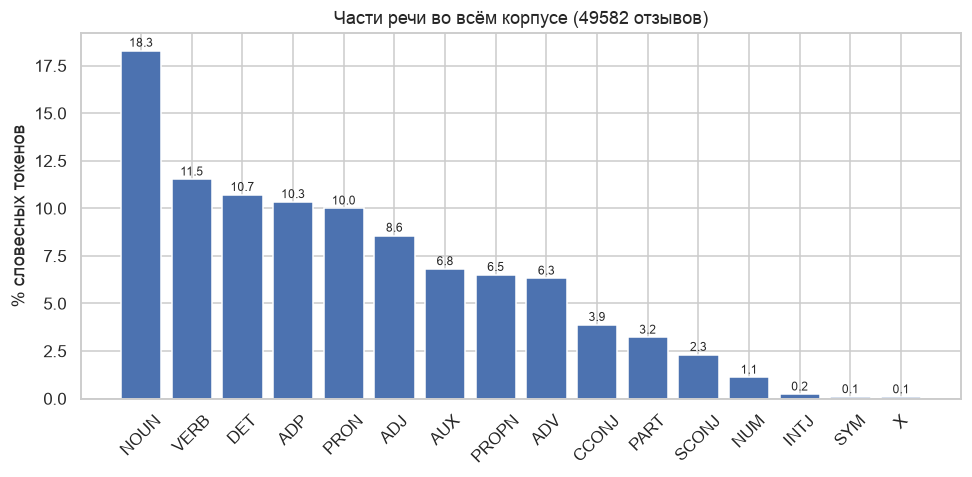

,NOUN,VERB,DET,ADP,PRON,ADJ,AUX,PROPN,ADV,CCONJ,PART,SCONJ,NUM,INTJ,SYM,X
токенов,2141702.0,1349128.00,1254172.00,1210277.00,1170574.0,1003559.00,797575.00,762031.00,739319.00,454549.00,376293.00,270093.00,130164.00,26182.00,10096.00,9264.00
"доля, %",18.3,11.53,10.71,10.34,10.0,8.57,6.81,6.51,6.32,3.88,3.21,2.31,1.11,0.22,0.09,0.08


In [5]:
pos_df = pd.DataFrame(agg["pos"], columns=UPOS)
WORD_POS = [p for p in UPOS if p not in ("PUNCT", "SPACE")]
word_tokens = pos_df[WORD_POS].sum(axis=1)
totals = pos_df.sum()
share = (totals[WORD_POS] / word_tokens.sum() * 100).sort_values(ascending=False)
print(f"Словесных токенов: {word_tokens.sum():,}, PUNCT: {totals['PUNCT']:,}, SPACE: {totals['SPACE']:,}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(share.index, share.values, color="#4C72B0")
for x, v in enumerate(share.values):
    ax.text(x, v + 0.2, f"{v:.1f}", ha="center", fontsize=8)
ax.set_title(f"Части речи во всём корпусе ({len(df)} отзывов)")
ax.set_ylabel("% словесных токенов")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_pos_distribution.png")
plt.show()
pd.DataFrame({"токенов": totals[share.index], "доля, %": share.round(2)}).T

#### Сравнение положительных и отрицательных отзывов

Два способа: частота на 1000 словесных токенов класса (все отзывы класса как один текст) и
средняя доля части речи в отдельном отзыве (каждый отзыв имеет одинаковый вес). Если оба способа
показывают одно направление, вывод устойчив к этим двум способам взвешивания.
Это само по себе не доказывает отсутствие выбросов или статистическую значимость.

In [6]:
is_pos = (df["sentiment"] == "positive").to_numpy()
per_1000 = pd.DataFrame({c: pos_df.loc[m, WORD_POS].sum() / word_tokens[m].sum() * 1000
                         for c, m in (("positive", is_pos), ("negative", ~is_pos))})
mean_share = (pos_df[WORD_POS].div(word_tokens, axis=0) * 100).groupby(df["sentiment"]).mean().T
compare = pd.DataFrame({
    "на 1000, pos": per_1000["positive"].round(1), "на 1000, neg": per_1000["negative"].round(1),
    "pos / neg": (per_1000["positive"] / per_1000["negative"]).round(2),
    "ср. доля в отзыве pos, %": mean_share["positive"].round(2),
    "ср. доля в отзыве neg, %": mean_share["negative"].round(2),
}).sort_values("pos / neg")
compare

,"на 1000, pos","на 1000, neg",pos / neg,"ср. доля в отзыве pos, %","ср. доля в отзыве neg, %"
INTJ,1.6,2.9,0.55,0.18,0.30
X,0.6,0.9,0.68,0.07,0.09
SYM,0.8,0.9,0.84,0.08,0.10
PART,30.2,34.1,0.89,2.94,3.41
AUX,64.8,71.6,0.90,6.72,7.40
SCONJ,22.1,24.1,0.92,2.15,2.34
ADV,61.1,65.2,0.94,6.17,6.54
VERB,112.1,118.5,0.95,11.20,11.80
NUM,11.0,11.2,0.98,1.13,1.16
PRON,98.8,101.3,0.98,10.20,10.25


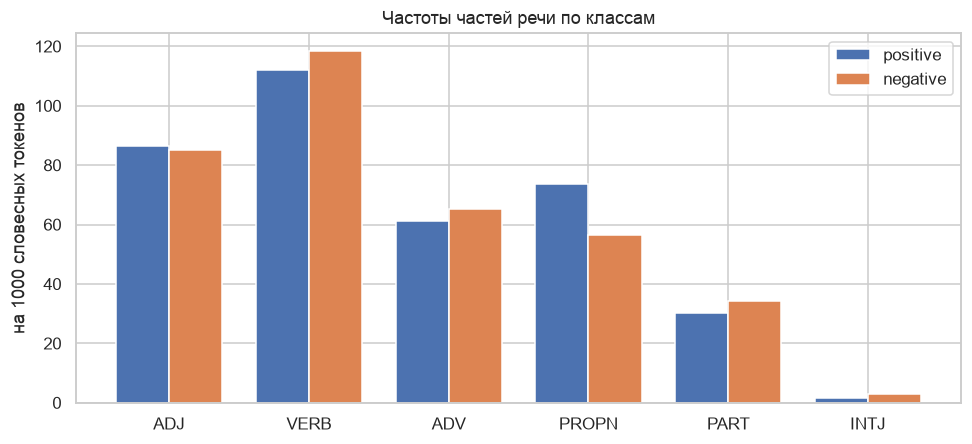

In [7]:
selected = ["ADJ", "VERB", "ADV", "PROPN", "PART", "INTJ"]
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(selected))
for k, cls in enumerate(["positive", "negative"]):
    ax.bar(x + (k - 0.5) * 0.38, per_1000.loc[selected, cls], width=0.38, label=cls, color=CLASS_COLORS[cls])
ax.set_xticks(x, selected)
ax.set_ylabel("на 1000 словесных токенов")
ax.set_title("Частоты частей речи по классам")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "02_pos_by_class.png")
plt.show()

Какие прилагательные сильнее всего связаны с классом: для каждой леммы считается сглаженный
логарифм отношения её относительных частот, `log2(((pos + 0.5) / N_pos) / ((neg + 0.5) / N_neg))`,
где `N` это число прилагательных в классе. Берутся леммы, встретившиеся не меньше 200 раз,
более редкие дают неустойчивое отношение.

In [8]:
MIN_COUNT = 200
cp, cn = agg["adj"]["positive"], agg["adj"]["negative"]
n_p, n_n = sum(cp.values()), sum(cn.values())
lemmas = [w for w in set(cp) | set(cn) if cp[w] + cn[w] >= MIN_COUNT and w.isalpha()]
ratio = pd.Series({w: np.log2(((cp[w] + 0.5) / n_p) / ((cn[w] + 0.5) / n_n)) for w in lemmas}).sort_values()
pd.DataFrame({"positive": [f"{w} ({ratio[w]:+.2f})" for w in ratio.index[::-1][:10]],
              "negative": [f"{w} ({ratio[w]:+.2f})" for w in ratio.index[:10]]}, index=range(1, 11))

,positive,negative
1,touching (+2.77),unwatchable (-3.78)
2,unforgettable (+2.69),unfunny (-3.63)
3,delightful (+2.69),incoherent (-3.61)
4,refreshing (+2.67),awful (-3.38)
5,timeless (+2.66),atrocious (-3.33)
6,superb (+2.61),laughable (-3.29)
7,underrated (+2.60),uninspired (-3.13)
8,extraordinary (+2.53),amateurish (-3.10)
9,magnificent (+2.48),pointless (-3.06)
10,outstanding (+2.34),lousy (-3.06)


Морфологические признаки: частоты значений числа, времени, степени сравнения и формы глагола
(доля внутри каждого признака).

In [9]:
morph = pd.Series(agg["morph"]).rename_axis(["признак", "значение"]).rename("токенов").reset_index()
morph["доля, %"] = (morph["токенов"] / morph.groupby("признак")["токенов"].transform("sum") * 100).round(1)
morph.sort_values(["признак", "токенов"], ascending=[True, False]).set_index(["признак", "значение"])

токенов  доля, %
признак  значение                  
Degree   Pos        945432     89.9
         Cmp         58045      5.5
         Sup         47703      4.5
Number   Sing      3899446     86.0
         Plur       634285     14.0
Tense    Pres       987866     63.5
         Past       567668     36.5
VerbForm Fin       1221822     57.4
         Part       452325     21.2
         Inf        442430     20.8
         Ger         12626      0.6

**Вывод по распределению.** Чаще всего встречаются существительные (18.3% словесных токенов),
глаголы (11.53%), определители (10.71%), предлоги (10.34%) и местоимения (10.0%), прилагательные
составляют 8.57%. Доля прилагательных в классах почти одинакова: 86.4 и 85.0 на 1000 слов, 8.82%
и 8.73% в среднем по отзыву; классы различаются набором прилагательных (`touching`, `superb`
против `unwatchable`, `awful`). Глаголы и междометия немного чаще в отрицательных отзывах (118.5
против 112.1 и 2.9 против 1.6 на 1000), имена собственные чаще в положительных (73.7 против 56.4):
это согласуется с более частым упоминанием имён, но требует отдельной проверки NER. Оба способа подсчёта дают одно направление, но различия
описательные, значимость не проверялась. В морфологии 63.5% форм с признаком времени стоят в
настоящем времени, сравнительная и превосходная степени составляют 5.5% и 4.5%.

#### Ошибки тэггера, вызванные шумом и сленгом

Кандидаты ищутся по форме токена, четыре признака:

1. слово из заглавных букв (от 3 букв) с тегом PROPN;
2. слово с удлинением букв (`sooo`, `BAAAAAD`) с тегом PROPN, NOUN или X;
3. склейка двух слов через знак конца предложения без пробела (`one!She`);
4. сленг и смайлики (`lol`, `wtf`, `hmm`, `:)`) с тегом не INTJ и не SYM.

Это кандидаты для ручного просмотра: например, `FBI` с тегом PROPN размечено верно.

In [10]:
SLANG = {"lol", "lmao", "omg", "wtf", "hmm", "hmmm", "ugh", "meh", "duh", "yay", "imo", "btw"}
EMOTICON_RE = re.compile(r"^[:;=][-o']?[()\[\]DPp/|]+$")
CHECKS = {
    "1 ALL-CAPS -> PROPN": lambda t: t.is_alpha and len(t) >= 3 and t.is_upper and t.pos_ == "PROPN",
    "2 удлинение букв": lambda t: t.is_alpha and bool(re.search(r"(\w)\1\1", t.text)) and t.pos_ in ("PROPN", "NOUN", "X"),
    "3 склейка через .!?": lambda t: re.fullmatch(r"[a-z]{2,}[.!?][A-Z][a-z]+", t.text) is not None,
    "4 сленг и смайлики": lambda t: (t.lower_ in SLANG or bool(EMOTICON_RE.match(t.text))) and t.pos_ not in ("INTJ", "SYM"),
}
cands = pd.DataFrame([(name, doc_id, tok.i) for doc_id, doc in iter_docs() for tok in doc
                      for name, check in CHECKS.items() if check(tok)], columns=["признак", "doc_id", "i"])
print(cands["признак"].value_counts().sort_index().to_string())


def context(doc, i, width=8):
    left, right = doc[max(0, i - width):i].text, doc[i + 1:i + 1 + width].text
    return f"{left} [[{doc[i].text}]] {right}".replace("\n", " / ")


sample = pd.concat([g.sample(5, random_state=SEED) for _, g in cands.groupby("признак")])
sample_docs = get_docs(sample["doc_id"])
sample.assign(тег=[sample_docs[d][i].pos_ for d, i in zip(sample["doc_id"], sample["i"])],
              контекст=[context(sample_docs[d], i) for d, i in zip(sample["doc_id"], sample["i"])]
              ).reset_index(drop=True)

признак
1 ALL-CAPS -> PROPN    29027
2 удлинение букв        1369
3 склейка через .!?      209
4 сленг и смайлики      1698


,признак,doc_id,i,тег,контекст
0,1 ALL-CAPS -> PROPN,28385,178,PROPN,"sister (future stand-up comedienne and [[MTV]] personality Julie Brown, whose striptease is a"
1,1 ALL-CAPS -> PROPN,18631,267,PROPN,", some 25 years later, had an [[ACTUAL]] ingenue been cast in such an important &"
2,1 ALL-CAPS -> PROPN,26235,196,PROPN,"Afghanistan has no Air Force, we ( [[USA]] ) control the skies. Also, this"
3,1 ALL-CAPS -> PROPN,31151,7,PROPN,This movie needs to be put on [[DVD]] . It was so funny and I loved
4,1 ALL-CAPS -> PROPN,2562,17,PROPN,Wesley Doyle (Powers Boothe) in his [[FBI]] office. He claims to have information about
5,2 удлинение букв,15205,19,PROPN,"it was all about. I thought "" [[hmmm]] , a movie named mutilation man must be"
6,2 удлинение букв,39248,391,PROPN,too strong would be a set back but [[nooo]] ... with every little problem the story throws
7,2 удлинение букв,25175,48,NOUN,be on that TV show because it was [[sooo]] bad. I'm sorry but I read
8,2 удлинение букв,20767,129,PROPN,"they´re ever going to be able making Part [[III]] , but I hope Von Trier will give"
9,2 удлинение букв,4795,126,PROPN,"wrong! I think the script for "" [[XXX]] "" was weak for which Vin couldn't"


Из кандидатов отобраны 8 проблемных случаев: 6 ошибок POS и 2 ошибки токенизации,
приводящие к неверной разметке склеенного токена. Ожидаемый UPOS указан по контексту;
SYM для смайлика соответствует рекомендациям Universal Dependencies.

In [11]:
ERRORS = [  # doc_id, номер токена, ожидаемый тег, причина
    (18631, 267, "ADJ", "заглавные буквы для выделения: 'an ACTUAL ingenue', определение при существительном"),
    (25175, 48, "ADV", "удлинение: 'it was sooo bad', наречие степени при прилагательном"),
    (15205, 19, "INTJ", "удлинение: '\"hmmm, a movie ...', междометие сомнения"),
    (39248, 391, "INTJ", "удлинение: 'but nooo...', восклицание"),
    (41088, 62, "NOUN + PUNCT + DET", "ошибка токенизации: film!My; My — притяжательный определитель"),
    (11228, 169, "ADJ + PUNCT + PRON", "нет пробела после '!': 'entertaining!What' склеено в один токен"),
    (4560, 589, "INTJ", "сленг: '(wtf?)', восклицание"),
    (3773, 591, "SYM", "смайлик ':P'; в UD смайлики размечаются как SYM"),
]
err_docs = get_docs([e[0] for e in ERRORS])
pd.DataFrame([{"токен": err_docs[d][i].text, "предсказано": err_docs[d][i].pos_, "должно быть": exp,
               "причина": why, "контекст": context(err_docs[d], i)} for d, i, exp, why in ERRORS],
             index=range(1, len(ERRORS) + 1))

,токен,предсказано,должно быть,причина,контекст
1,ACTUAL,PROPN,ADJ,"заглавные буквы для выделения: 'an ACTUAL ingenue', определение при существительном",", some 25 years later, had an [[ACTUAL]] ingenue been cast in such an important &"
2,sooo,NOUN,ADV,"удлинение: 'it was sooo bad', наречие степени при прилагательном",be on that TV show because it was [[sooo]] bad. I'm sorry but I read
3,hmmm,PROPN,INTJ,"удлинение: '""hmmm, a movie ...', междометие сомнения","it was all about. I thought "" [[hmmm]] , a movie named mutilation man must be"
4,nooo,PROPN,INTJ,"удлинение: 'but nooo...', восклицание",too strong would be a set back but [[nooo]] ... with every little problem the story throws
5,film!My,PROPN,NOUN + PUNCT + DET,ошибка токенизации: film!My; My — притяжательный определитель,executioner but apparently not after watching the whole [[film!My]] only real gripe is the acting of the
6,entertaining!What,ADP,ADJ + PUNCT + PRON,нет пробела после '!': 'entertaining!What' склеено в один токен,"this movie is almost perfect, and completely [[entertaining!What]] a funny screenplay! It also has become"
7,wtf,PROPN,INTJ,"сленг: '(wtf?)', восклицание",he punches his fist through the window ( [[wtf]] ?) / The ending is the only
8,:P,PROPN,SYM,смайлик ':P'; в UD смайлики размечаются как SYM,screen time. Maybe that. End Spoiler [[:P]] / If this movie was made for the


Проверка регистра для случаев с заглавными буквами: в исходном отзыве в нижний регистр
переводится только целевое слово, отзыв размечается заново, и смотрится, изменился ли тег. Это
показывает чувствительность конкретного случая к регистру. Переводить весь корпус в нижний
регистр из этого не следует: регистр помогает узнавать имена.

In [12]:
caps = sample[sample["признак"].str.startswith("1")]
rows = []
for d, i in zip(caps["doc_id"], caps["i"]):
    tok = sample_docs[d][i]
    text = sample_docs[d].text
    flipped = nlp(text[:tok.idx] + tok.text.lower() + text[tok.idx + len(tok):])
    new = next(t for t in flipped if t.idx == tok.idx)
    rows.append({"токен": tok.text, "тег в исходном": tok.pos_, "тег после нижнего регистра": new.pos_})
pd.DataFrame(rows)

,токен,тег в исходном,тег после нижнего регистра
0,MTV,PROPN,PROPN
1,ACTUAL,PROPN,ADJ
2,USA,PROPN,PROPN
3,DVD,PROPN,PROPN
4,FBI,PROPN,PROPN


**Вывод по ошибкам.** Признаки дали 29027 ALL-CAPS слов с тегом PROPN, 1369 слов с удлинением,
209 склеек и 1698 сленговых слов и смайликов с подозрительным тегом. Разобраны 8 ошибок: ALL-CAPS
для выделения, удлинения, склейки без пробела, сленг и смайлик. Проверка регистра: `ACTUAL` после
перевода в нижний регистр становится ADJ, а верные аббревиатуры `MTV`, `USA`, `DVD`, `FBI`
остаются PROPN. Ошибка `ACTUAL` вызвана регистром, но переводить весь корпус в нижний регистр не
стоит: 4 из 5 проверенных ALL-CAPS слов размечены верно.

### Шаг 3. Деревья зависимостей

Модель использует метки ClearNLP, они немного отличаются от UD v2. Для Шага 4 важны: `nsubj`
(подлежащее), `amod` (прилагательное-определение), `acomp` и `oprd` (прилагательное в роли
именной части сказуемого при связке `be`, `seem`), `neg` (отрицание), `conj` (однородный член),
`compound` (первая часть составного существительного). В отличие от UD, вершиной предложения
*the plot was boring* остаётся связка `was`, к ней крепятся и `plot`, и `boring`.

Средняя длина объявлена как 12-25 словесных токенов. Предложения берутся из случайных 3000
отзывов (seed 42), без остатков разметки и с конечным знаком препинания, не больше одного
предложения из отзыва. После отбора выводится, какие конструкции в них есть.

In [13]:
def is_medium_clean(sent):
    words = sum(not t.is_punct and not t.is_space for t in sent)
    text = sent.text.strip()
    return 12 <= words <= 25 and not re.search(r"[<>*/_|\n]|http", text) and text[-1:] in ".!?"


rng = random.Random(SEED)
pool_ids = set(rng.sample(range(len(df)), 3000))
pool = {}
for doc_id, doc in iter_docs():
    good = [s for s in doc.sents if is_medium_clean(s)] if doc_id in pool_ids else []
    if good:
        pool[doc_id] = rng.choice(good)
chosen = [pool[d] for d in rng.sample(sorted(pool), 10)]

FLAGS = {"amod": "amod", "acomp": "связка+прил.", "dobj": "прямое доп.", "neg": "отрицание",
         "conj": "сочинение", "relcl": "придаточное"}
pd.DataFrame({"предложение": [s.text.strip() for s in chosen],
              "конструкции": [", ".join(v for k, v in FLAGS.items() if any(t.dep_ == k for t in s)) for s in chosen]},
             index=range(1, 11))

,предложение,конструкции
1,It also sends a message that we should all know and learn from.,"прямое доп., сочинение"
2,Both the book and the film are excellent in their own right.,"amod, связка+прил., сочинение"
3,"Well, I would highly recommend this remarkable piece of ""Art"" for anyone interested in thought-provoking independent cinema.","amod, прямое доп."
4,"To skip ahead, Martel finances a film for Mateo so he can keep tabs on the star of the film, Lena.",прямое доп.
5,I highly recommend it to people of all ages and especially to animal lovers.,"прямое доп., сочинение"
6,"Daniel Day-Lewis is a chameleon, really hard to imagine how much effort he had done to create this disabled character.","amod, прямое доп."
7,"If they can spice it up with a little interaction between the characters, even better.","amod, прямое доп."
8,"Not knowing what this film was about, I checked it out at the video store and after seeing it, I enjoyed it.","прямое доп., отрицание, сочинение"
9,"In addition, the excellent acting by Lorre shows that he was capable of more than just supporting roles.","amod, связка+прил., прямое доп."
10,"Its a shame a big studio and direct wont risk it, no more super hero films please!","amod, прямое доп., отрицание, сочинение"


Схемы строятся `displacy` и сохраняются в `figures/deps/`. Слова раскрашены по части речи:
существительные синие, прилагательные зелёные, глаголы красные, местоимения оранжевые.

1. It also sends a message that we should all know and learn from.


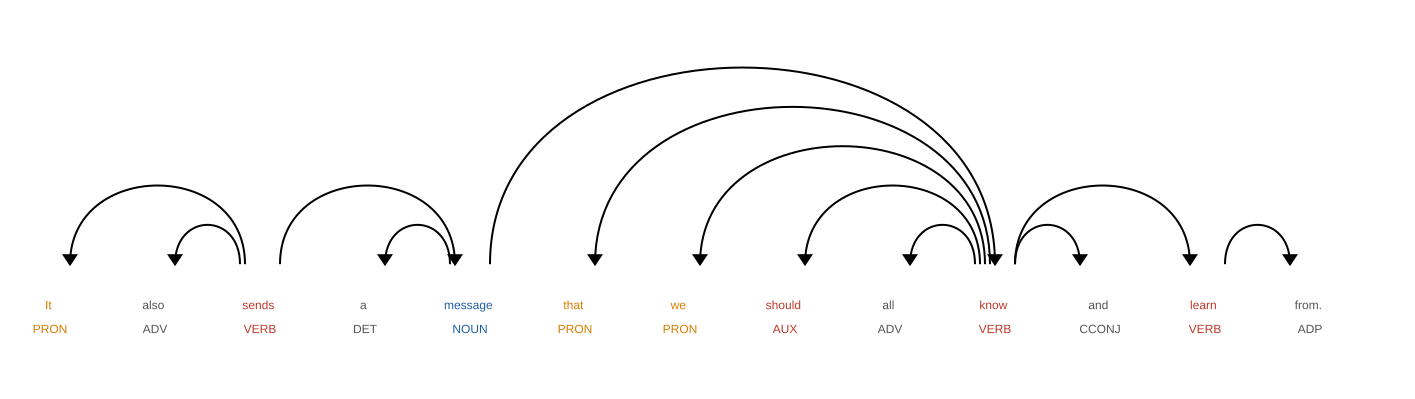

2. Both the book and the film are excellent in their own right.


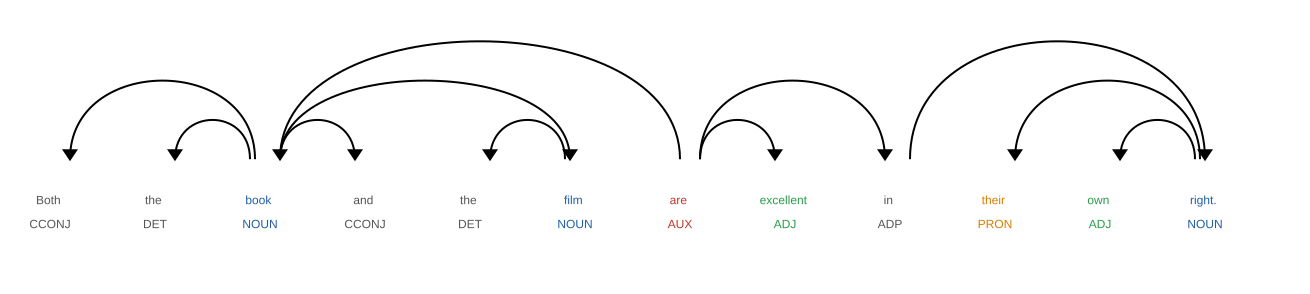

3. Well, I would highly recommend this remarkable piece of "Art" for anyone interested in thought-provoking independent cinema.


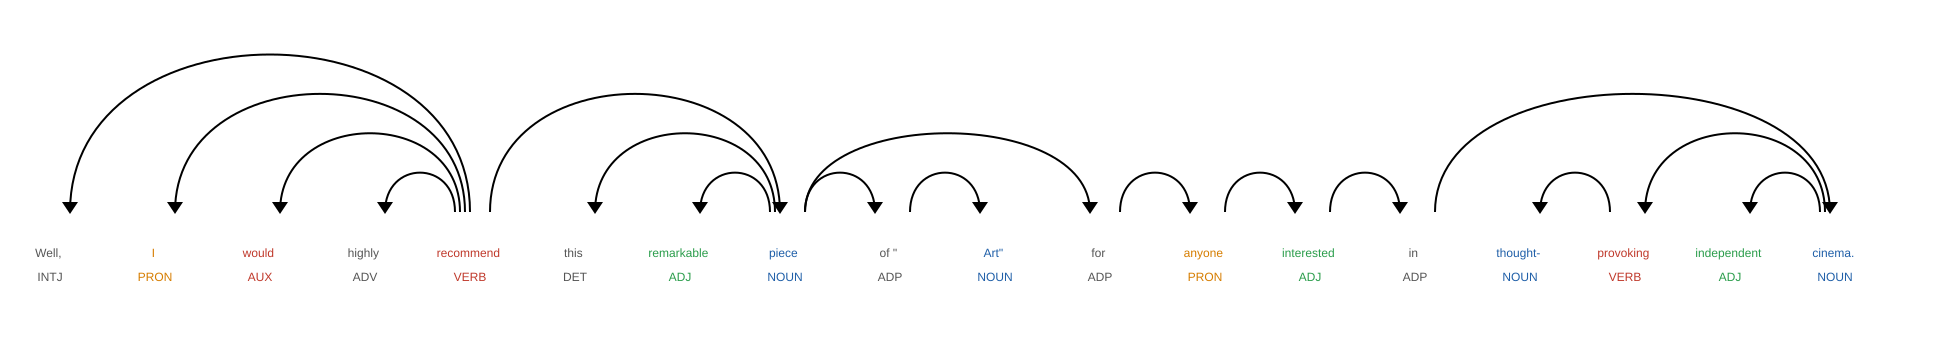

4. To skip ahead, Martel finances a film for Mateo so he can keep tabs on the star of the film, Lena.


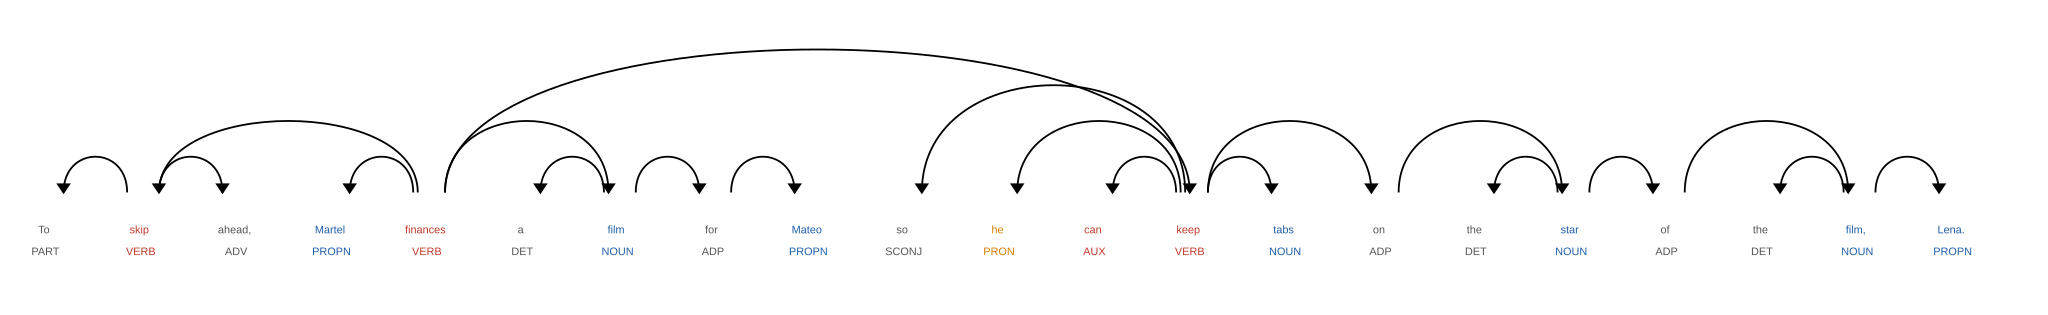

5. I highly recommend it to people of all ages and especially to animal lovers.


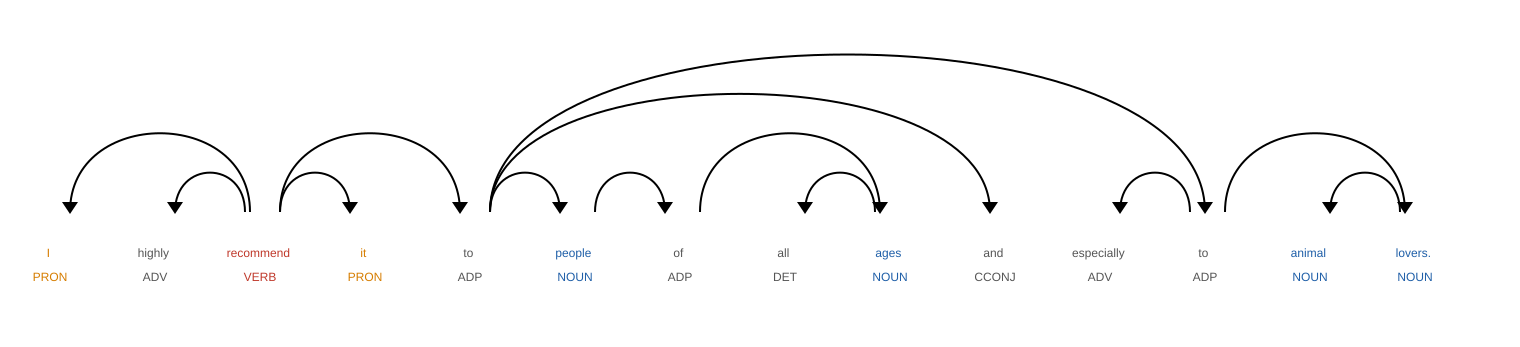

6. Daniel Day-Lewis is a chameleon, really hard to imagine how much effort he had done to create this disabled character.


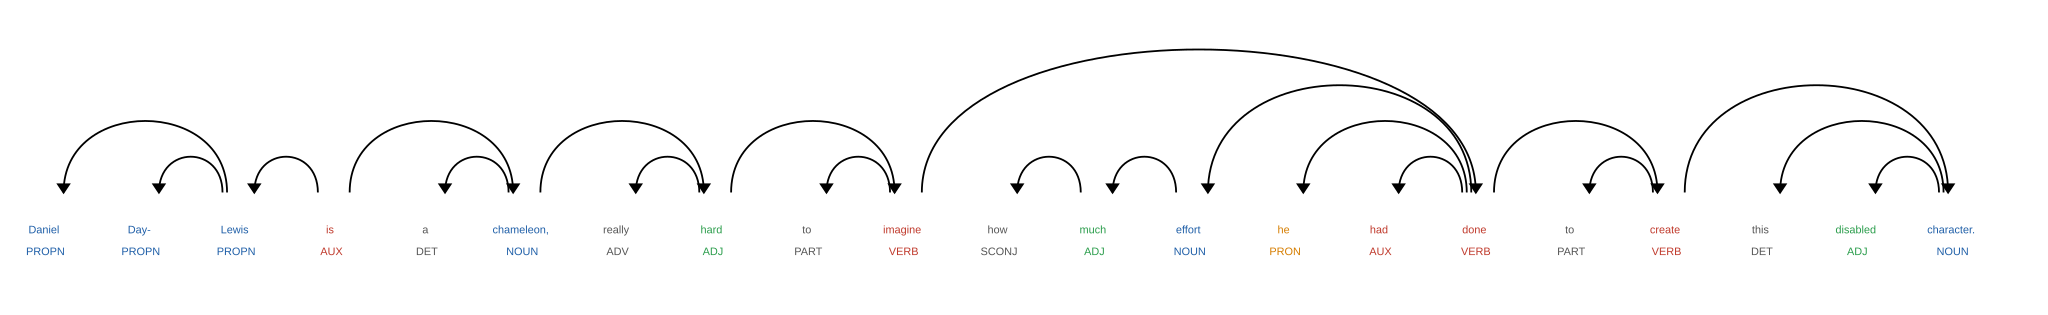

7. If they can spice it up with a little interaction between the characters, even better.


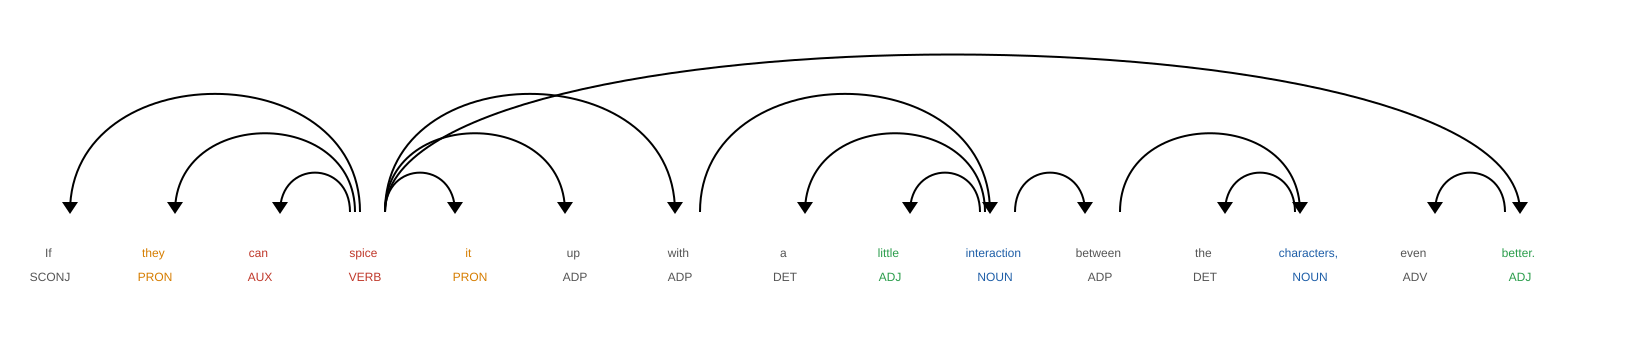

8. Not knowing what this film was about, I checked it out at the video store and after seeing it, I enjoyed it.


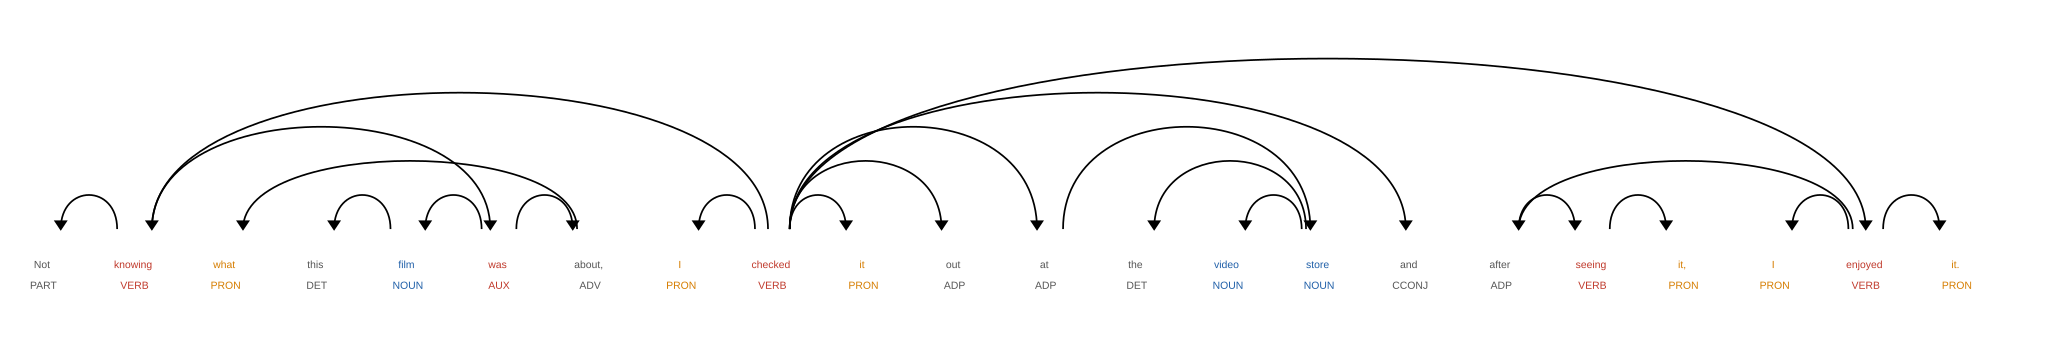

9. In addition, the excellent acting by Lorre shows that he was capable of more than just supporting roles.


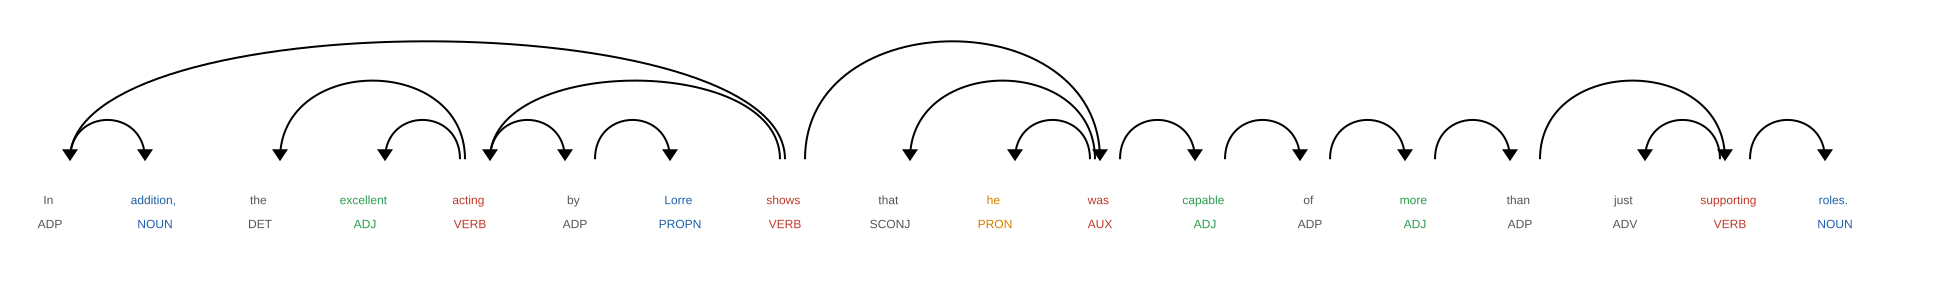

10. Its a shame a big studio and direct wont risk it, no more super hero films please!


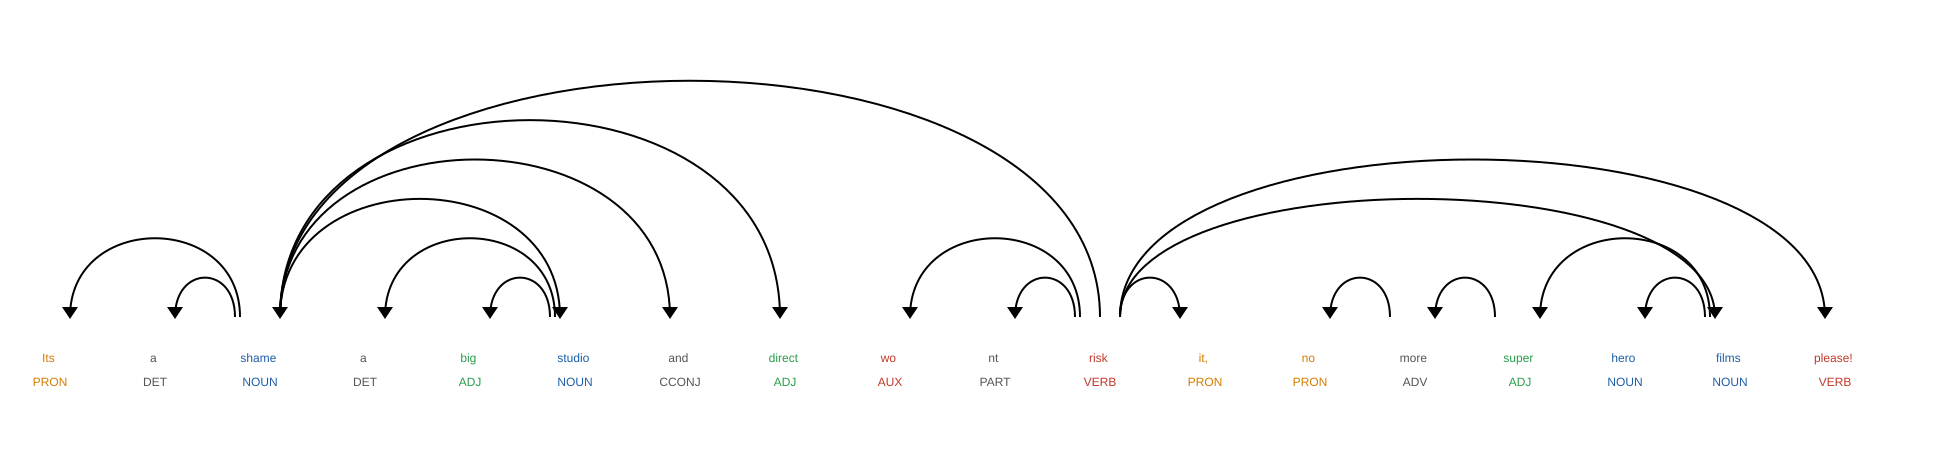

In [14]:
POS_COLORS = {"NOUN": "#1f5fa8", "PROPN": "#1f5fa8", "ADJ": "#2a9d4b", "VERB": "#c0392b",
              "AUX": "#c0392b", "PRON": "#d67d00"}


def color_by_pos(svg):
    """Fill each word and its tag with the colour of its part of speech."""
    def paint(m):
        tag = re.search(r'class="displacy-tag"[^>]*>([^<]*)<', m.group(0)).group(1)
        return m.group(0).replace('fill="currentColor"', f'fill="{POS_COLORS.get(tag, "#555555")}"')
    return re.sub(r'<text class="displacy-token".*?</text>', paint, svg, flags=re.S)


for n, sent in enumerate(chosen, 1):
    svg = color_by_pos(displacy.render(sent.as_doc(), style="dep", jupyter=False,
                                       options={"distance": 105, "font": "Arial"}))
    (FIG_DIR / "deps" / f"dep_{n:02d}.svg").write_text(svg, encoding="utf-8")
    print(f"{n}. {sent.text.strip()}")
    display(SVG(svg))

Что видно на схемах (связи, важные для Шага 4):

1. Главный глагол `sends` с прямым дополнением `message` (`dobj`), к `message` присоединено
   придаточное с `know` (`acl`), к нему однородное `learn` (`conj`). Прилагательных нет.
2. Однородные подлежащие `book` и `film` (`conj`) при связке `are`, прилагательное `excellent`
   (`acomp`). Правила 2 и 3 дают две пары: `book - excellent` и `film - excellent`.
3. `remarkable` зависит от `piece` по `amod`: пара `piece - remarkable`. `interested` относится к
   местоимению `anyone`, такие пары не берутся.
4. `film` — прямое дополнение (`dobj`) при `finances`, придаточное цели `keep` (`advcl`).
   `Lena` присоединена к `film` как приложение (`appos`), по смыслу это `star`.
5. `it` прямое дополнение при `recommend`, два дополнения с `to` соединены через `conj`;
   `animal` — зависимый `compound` при `lovers`: составное существительное.
6. Ошибка разбора: `hard` присоединено как `amod` к `chameleon`, хотя это сказуемое
   пропущенного *it is hard to imagine*. Отсюда ложная пара `chameleon - hard`; `disabled`
   зависит от `character` по `amod` и даёт верную описательную пару.
7. `little` зависит от `interaction` по `amod`: пара `interaction - little`. `better` без
   существительного (`advmod` при `spice`), пары нет.
8. Отрицание `Not` (`neg`) относится к `knowing`. Действия `checked` и `enjoyed` соединены
   через `conj`. Прилагательных нет.
9. Ошибка тэггера: `acting` размечено как VERB, поэтому пара `acting - excellent` не
   извлекается. `capable` (`acomp`) при `was` с подлежащим `he`: местоимение, пары нет.
10. Шум ломает разбор: `Its` вместо *it's* и `wont` без апострофа, `shame` стало подлежащим при
    `risk`, опечатка `direct` (director) размечена как ADJ. `nt` (`neg`) висит на `risk`;
    `super` зависит от `films` по `amod` и даёт пару `film - super`.

### Шаг 4. Извлечение пар аспект-оценка

Функция обходит дерево предложения и для каждого прилагательного ищет существительное, которое
оно оценивает:

1. **определение** (`amod`): *great acting* -> (acting, great);
2. **сказуемое со связкой** (`acomp` или `oprd` при be, seem, look, feel, ...): *the plot was
   boring* -> (plot, boring), аспект это подлежащее связки;
3. **однородные члены** (`conj`): *wooden and dull* даёт две пары, *plot and acting were bad*
   тоже две;
4. **отрицание**: если `neg` висит на прилагательном или на связке (*was not funny*, *is not a
   good movie*), пара помечается как отрицательная;
5. **составной аспект**: `compound`-существительные входят в аспект (*horror movie*);
6. местоимения аспектом не считаются (*it was boring* пары не даёт).

Несколько прилагательных с функцией числительного или определителя (`other`, `same`, `many`,
`first`, `only`) оценкой не считаются. Лемматизатор spaCy даёт для `better` лемму `well`, поэтому
леммы `better`, `best`, `worse`, `worst` заданы явно.

In [15]:
LINKING_VERBS = {"be", "seem", "look", "feel", "appear", "become", "remain", "sound", "get"}
NOT_OPINION = {"other", "same", "such", "many", "much", "more", "most", "own", "first", "last", "only", "whole"}
IRREGULAR = {"better": "good", "best": "good", "worse": "bad", "worst": "bad"}


def adj_lemma(tok):
    return IRREGULAR.get(tok.lower_, tok.lemma_.lower())


def is_candidate_adj(tok):
    in_hyphen_word = tok.whitespace_ == "" and tok.i + 1 < len(tok.doc) and tok.nbor().text == "-"
    return tok.pos_ == "ADJ" and tok.is_alpha and not in_hyphen_word and adj_lemma(tok) not in NOT_OPINION


def is_aspect_noun(tok):
    return tok.pos_ == "NOUN" and tok.is_alpha


def has_neg(tok):
    return any(c.dep_ == "neg" for c in tok.children)


def aspect_name(noun):
    parts = [c for c in noun.children if c.dep_ == "compound" and c.pos_ == "NOUN" and c.i < noun.i]
    return " ".join(t.lemma_.lower() for t in parts + [noun])


def target_nouns(adj):
    """Nouns described by adj and the negation flag; empty list if there is no noun target."""
    head = adj.head
    if adj.dep_ == "amod" and is_aspect_noun(head):
        return [head], has_neg(adj) or (head.dep_ == "attr" and has_neg(head.head))
    if adj.dep_ in ("acomp", "oprd") and head.lemma_.lower() in LINKING_VERBS:
        subjects = [c for c in head.children if c.dep_ == "nsubj" and is_aspect_noun(c)]
        nouns = [n for s in subjects for n in [s] + [c for c in s.conjuncts if is_aspect_noun(c)]]
        return nouns, has_neg(head) or has_neg(adj)
    return [], False


def extract_pairs(sent):
    pairs = []
    for tok in sent:
        if not is_candidate_adj(tok) or tok.dep_ == "conj":
            continue
        nouns, negated = target_nouns(tok)
        for adj in [tok] + [c for c in tok.conjuncts if is_candidate_adj(c)]:
            for noun in nouns:
                pairs.append({"aspect": aspect_name(noun), "opinion": adj_lemma(adj), "negated": negated,
                              "noun_i": noun.i, "adj_i": adj.i})
    return pairs



# Этот слой не удаляет структурные пары и не определяет тональность отзыва.
EVALUATIVE_ADJ = {"good", "bad", "great", "excellent", "awful", "terrible", "wonderful",
                  "amazing", "boring", "enjoyable", "fun", "funny", "tame", "lame",
                  "meticulous", "wise", "okay", "exceptional", "dramatic", "precious",
                  "stupid", "silly", "classic", "superb", "poor", "brilliant", "dull",
                  "wooden", "predictable", "unwatchable", "beautiful", "horrible"}
DESCRIPTIVE_ADJ = {"next", "few", "young", "old", "little", "human", "main", "new",
                   "previous", "annual", "daily", "male", "female", "angry"}
DESCRIPTIVE_TERMS = {("comedy", "romantic"), ("effect", "special"),
                     ("school", "high"), ("life", "real"), ("close up", "extreme"),
                     ("blacklist", "unbreakable")}


def classify_pair(aspect, opinion):
    """Conservative lexical screening: evaluative / descriptive / uncertain."""
    if (aspect, opinion) in DESCRIPTIVE_TERMS or opinion in DESCRIPTIVE_ADJ:
        return "описательная"
    if opinion in EVALUATIVE_ADJ:
        return "оценочная"
    return "неопределённая"


def pair_set(text):
    return {(p["aspect"], p["opinion"], p["negated"]) for p in extract_pairs(nlp(text))}


assert pair_set("It has great acting.") == {("acting", "great", False)}
assert pair_set("The plot was boring.") == {("plot", "boring", False)}
assert pair_set("The acting was wooden and dull.") == {("acting", "wooden", False), ("acting", "dull", False)}
assert pair_set("The plot and the acting were bad.") == {("plot", "bad", False), ("acting", "bad", False)}
assert pair_set("The jokes were not funny.") == {("joke", "funny", True)}
assert pair_set("The horror movie was scary.") == {("horror movie", "scary", False)}
assert pair_set("It was boring.") == set()
print("Проверки на примерах пройдены")

Проверки на примерах пройдены


In [16]:
t0 = time.time()
pairs = pd.DataFrame([{"doc_id": doc_id, "sent_id": k, **p} for doc_id, doc in iter_docs()
                      for k, sent in enumerate(doc.sents) for p in extract_pairs(sent)])
pairs["sentiment"] = df["sentiment"].to_numpy()[pairs["doc_id"]]
pairs["тип по правилам"] = [classify_pair(a, o) for a, o in zip(pairs["aspect"], pairs["opinion"])]
pairs["pair"] = pairs["aspect"] + " - " + np.where(pairs["negated"], "NOT ", "") + pairs["opinion"]
print(f"Пар: {len(pairs):,} из {pairs['doc_id'].nunique():,} отзывов, с отрицанием: {pairs['negated'].sum():,} "
      f"({time.time() - t0:.0f} c)")

Пар: 598,027 из 49,313 отзывов, с отрицанием: 10,821 (10 c)


#### Проверка точности на случайной выборке

Случайно (seed 42) берутся 30 извлечённых пар. Критерий структурной корректности:
прилагательное относится к указанному существительному и верно учтено отрицание;
слово-заместитель `ones` не считается содержательным аспектом. Описательные, временные,
количественные и терминологические сочетания считаются корректными связями, но сами
по себе не доказывают наличие оценки. Поэтому эта метрика не является точностью
распознавания тональности. Проверка выполнена по контексту, без независимых аннотаторов.

In [17]:
def mark(sent, marks):
    """Sentence text with chosen tokens wrapped, marks = {token index: (left, right)}."""
    return "".join(f"{marks.get(t.i, ('', ''))[0]}{t.text}{marks.get(t.i, ('', ''))[1]}{t.whitespace_}"
                   for t in sent).strip().replace("\n", " ")


pair_check = pairs.sample(30, random_state=SEED).reset_index(drop=True)
check_docs = get_docs(pair_check["doc_id"])
pair_check["предложение"] = [mark(list(check_docs[r.doc_id].sents)[r.sent_id],
                                  {r.noun_i: ("[[", "]]"), r.adj_i: ("{{", "}}")}) for r in pair_check.itertuples()]
pair_check[["pair", "предложение"]]

,pair,предложение
0,hour - next,"In the course of the {{next}} [[hour]] another guy gets whacked crossing the street, there's a shootout with several stiffs in a warehouse, some car chases with wreckage & death, a fake suicide, e..."
1,blacklist - unbreakable,"Remarkable Noir picture that defines 1950s French Cinema. Spartacus(1960) may have been the one which broke down the infamous blacklist, but in my opinion Rififi(1955) was the film that began to b..."
2,woman - angry,"A few blocks later, they pass an old Filipino [[woman]], also {{angry}}, also arguing on a cell phone, and Luca remarks, for referential effect, ""There's nothing hotter than an angry, elderly Fili..."
3,humor - tame,"Even the anti-religious [[humor]] is {{tame}} (and lame, caricatured, insincere, derivative, unoriginal, and worst of all not funny in the slightest--it would be better just to listen to Ray Steve..."
4,film - great,"I saw the world premiere at the Toronto International Film Fest, this is a {{great}} [[film]]."
5,artist - meticulous,"With his distinguishing visual style and his taste for solemn material, he gained a reputation as a {{meticulous}}, serious [[artist]]..."
6,movie - enjoyable,"Most of the things that make a terrible [[movie]] {{enjoyable}} are here: bad dialogue, inappropriate music, contrived plot sequences, ridiculous pseudoscience."
7,satire - fun,"This Alec Guinness starrer is a very good {{fun}} political [[satire]] of corporate industry, and a light eccentric character study as well."
8,scene - few,"I wanted to laugh at a {{few}} [[scenes]] and cry at others, and that was only because of how pitiful it was."
9,woman - wise,"The amazing Anne Revere, as Mrs. Brown, seemed to be the {{wisest}} [[woman]] in the world."


Контекстная проверка разделяет два вопроса: корректна ли извлечённая связь
с учётом отрицания и выражает ли она оценку. Критерий оценки — суждение о качестве,
достоинствах или недостатках аспекта. Время, количество, возраст, жанровый термин,
технический масштаб кадра и эмоциональное состояние персонажа — описания.
`divisive`, `unusual`, `basic` в выбранных контекстах оставлены неопределёнными:
их оценочное прочтение требует дополнительной интерпретации.

Словарный слой `classify_pair` применяется ко всему корпусу: сначала проверяются
описательные сочетания, затем фиксированный список оценочных лемм, прочие случаи
остаются неопределёнными. Это эвристика, а не обученный классификатор или эталон.
Контекстные метки ниже определены отдельно по полным предложениям; независимых
аннотаторов нет. Неопределённые случаи не считаются подтверждёнными оценками.
Словари и критерии иллюстративные: эта выборка не является независимым тестом
качества нового словарного слоя. Для такой проверки нужна новая размеченная выборка.

In [18]:
PAIR_LABELS = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1]
PAIR_NOTES = {
    0: "next hour: время", 1: "unbreakable blacklist: характеристика устойчивости запрета",
    2: "angry woman: состояние персонажа, не оценка качества",
    8: "few scenes: количество", 10: "ones: слово-заместитель, не аспект; young — возраст",
    13: "divisive film: неоднозначная характеристика реакции аудитории",
    14: "extreme close-ups: технический тип кадра",
    16: "neither ... nor: оценка есть, но отрицание не найдено",
    17: "romantic comedy: жанр", 18: "unusual thing: необычность без явной оценки качества",
    19: "human nature: устойчивое сочетание",
    22: "Not an exceptional effort: оценка есть, но отрицание не найдено",
    23: "little boy: возраст", 25: "good idea: оценка внутри иронически отвергаемого суждения",
    27: "basic story: описание структуры, оценочное прочтение неочевидно",
}
D, E, U = "описательная", "оценочная", "неопределённая"
PAIR_CONTEXT_TYPES = [D, D, D, E, E, E, E, E, D, E, D, E, E, U, D,
                      E, E, D, U, D, E, E, E, D, E, E, E, U, E, E]
assert pair_check["pair"].head(3).tolist() == ["hour - next", "blacklist - unbreakable", "woman - angry"]
assert len(PAIR_CONTEXT_TYPES) == len(PAIR_LABELS) == len(pair_check)
pair_check["метка"] = PAIR_LABELS
pair_check["тип по контексту"] = PAIR_CONTEXT_TYPES
pair_check["корректная оценочная пара"] = (
    pair_check["метка"].eq(1) & pair_check["тип по контексту"].eq(E)
).astype(int)
pair_check["комментарий"] = pd.Series(PAIR_NOTES)
structural_n = int(pair_check["метка"].sum())
evaluative_n = int(pair_check["корректная оценочная пара"].sum())
print(f"Структурно корректных пар: {structural_n}/30 = {structural_n / 30:.1%}")
print(f"Корректных оценочных пар среди всех извлечённых: {evaluative_n}/30 = {evaluative_n / 30:.1%}")
print("Типы по контексту:", pair_check["тип по контексту"].value_counts().to_dict())
with pd.option_context("display.max_colwidth", None):
    display(pair_check[["pair", "предложение", "метка", "тип по правилам", "тип по контексту",
                        "корректная оценочная пара", "комментарий"]].fillna(""))

Структурно корректных пар: 27/30 = 90.0%
Корректных оценочных пар среди всех извлечённых: 16/30 = 53.3%
Типы по контексту: {'оценочная': 18, 'описательная': 9, 'неопределённая': 3}


,pair,предложение,метка,тип по правилам,тип по контексту,корректная оценочная пара,комментарий
0,hour - next,"In the course of the {{next}} [[hour]] another guy gets whacked crossing the street, there's a shootout with several stiffs in a warehouse, some car chases with wreckage & death, a fake suicide, etc. etc.",1,описательная,описательная,0,next hour: время
1,blacklist - unbreakable,"Remarkable Noir picture that defines 1950s French Cinema. Spartacus(1960) may have been the one which broke down the infamous blacklist, but in my opinion Rififi(1955) was the film that began to break apart the {{unbreakable}} Hollywood [[blacklist]].",1,описательная,описательная,0,unbreakable blacklist: характеристика устойчивости запрета
2,woman - angry,"A few blocks later, they pass an old Filipino [[woman]], also {{angry}}, also arguing on a cell phone, and Luca remarks, for referential effect, ""There's nothing hotter than an angry, elderly Filipino woman.",1,описательная,описательная,0,"angry woman: состояние персонажа, не оценка качества"
3,humor - tame,"Even the anti-religious [[humor]] is {{tame}} (and lame, caricatured, insincere, derivative, unoriginal, and worst of all not funny in the slightest--it would be better just to listen to Ray Stevens' ""Would Jesus Wear a Rolex on His Television Show"").",1,оценочная,оценочная,1,
4,film - great,"I saw the world premiere at the Toronto International Film Fest, this is a {{great}} [[film]].",1,оценочная,оценочная,1,
5,artist - meticulous,"With his distinguishing visual style and his taste for solemn material, he gained a reputation as a {{meticulous}}, serious [[artist]]...",1,оценочная,оценочная,1,
6,movie - enjoyable,"Most of the things that make a terrible [[movie]] {{enjoyable}} are here: bad dialogue, inappropriate music, contrived plot sequences, ridiculous pseudoscience.",1,оценочная,оценочная,1,
7,satire - fun,"This Alec Guinness starrer is a very good {{fun}} political [[satire]] of corporate industry, and a light eccentric character study as well.",1,оценочная,оценочная,1,
8,scene - few,"I wanted to laugh at a {{few}} [[scenes]] and cry at others, and that was only because of how pitiful it was.",1,описательная,описательная,0,few scenes: количество
9,woman - wise,"The amazing Anne Revere, as Mrs. Brown, seemed to be the {{wisest}} [[woman]] in the world.",1,оценочная,оценочная,1,


**Вывод по Шагу 4.** Функция извлекла 598 027 пар из 49 313 отзывов, 10 821 из них с
отрицанием. На случайной выборке структурно корректны 27 из 30 пар (90.0%).
Ошибки: слово-заместитель вместо содержательного аспекта (`young ones`) и отрицание
вне правил (`neither ... nor`, отрывок `Not an exceptional effort`).
`next hour`, `few scenes`, `romantic comedy`, `human nature` структурно корректны, но
не являются оценками. Поэтому 90.0% нельзя трактовать как точность извлечения мнений.
Отдельная контекстная оценка: 18 пар оценочные, 9 описательные, 3 неопределённые.
Из 18 оценочных у 2 неверно передано отрицание. Поэтому доля корректных оценочных
пар среди всех извлечённых равна 16/30 = 53.3%. Оба показателя используют один
знаменатель, но разные критерии. При таком строгом критерии `angry woman` описывает
состояние персонажа, а `extreme close-ups` — тип кадра. Это не ошибки синтаксиса.
Оценочная пара также может относиться к персонажу или книге, а не к самому фильму.
Метрики относятся только к этой небольшой выборке; независимой экспертной оценки нет.
Схема 9 показывает и пропуски: если тэггер ошибся (`acting` как VERB), пара не извлекается. Полнота не измерялась.

### Шаг 5. Топ-20 пар и их анализ

Частота пары считается по вхождениям, рядом указано число разных отзывов, где пара встретилась.
Пара с отрицанием показана как `acting - NOT good`.

In [19]:
top20 = pairs.groupby("pair").agg(вхождений=("doc_id", "size"), отзывов=("doc_id", "nunique"),
                                  доля_в_positive=("sentiment", lambda s: round((s == "positive").mean() * 100, 1)))
top20 = top20.sort_values("вхождений", ascending=False).head(20)
print(f"Уникальных пар: {pairs['pair'].nunique():,}")
top20

Уникальных пар: 257,783


,вхождений,отзывов,доля_в_positive
pair,,,
movie - bad,2884,2407,5.9
movie - good,2752,2528,54.8
effect - special,2246,1952,35.4
film - good,1890,1758,61.8
character - main,1887,1645,43.7
film - bad,1317,1152,5.3
thing - good,1226,1172,32.7
movie - great,1208,1115,75.0
guy - bad,1167,927,36.9


Отдельный словарный слой сохраняет все пары, но помечает их предполагаемую функцию.
Ниже приведены число вхождений по типам и топ-20 предварительно оценочных пар.
Контекст, ирония и область действия отрицания этим слоем полностью не разрешаются.

In [20]:
pair_types = pairs["тип по правилам"].value_counts().rename_axis("тип").to_frame("вхождений")
pair_types["доля, %"] = (pair_types["вхождений"] / len(pairs) * 100).round(2)
display(pair_types)
top20_evaluative = (pairs.loc[pairs["тип по правилам"].eq("оценочная")]
                    .groupby("pair").agg(вхождений=("doc_id", "size"), отзывов=("doc_id", "nunique"))
                    .sort_values("вхождений", ascending=False).head(20))
display(top20_evaluative)

,вхождений,"доля, %"
тип,,
неопределённая,447769,74.87
оценочная,103887,17.37
описательная,46371,7.75


,вхождений,отзывов
pair,,
movie - bad,2884,2407
movie - good,2752,2528
film - good,1890,1758
film - bad,1317,1152
thing - good,1226,1172
movie - great,1208,1115
guy - bad,1167,927
film - great,938,882
performance - good,932,887


In [21]:
pd.concat({cls: pairs.loc[pairs["sentiment"] == cls, "pair"].value_counts().head(5).reset_index()
           for cls in ("positive", "negative")}, axis=1)

positive                negative      
               pair count              pair count
0      movie - good  1509       movie - bad  2713
1       film - good  1168  effect - special  1450
2     movie - great   906        film - bad  1247
3  character - main   824      movie - good  1243
4  effect - special   796  character - main  1063

**Прилагательные, оценка которых зависит от жанра.** Для фильма ужасов `scary` может быть
похвалой, для драмы `dark` или `brutal` тоже. Ниже доля употреблений (без отрицания) в
положительных отзывах; для сравнения выводится доля положительных отзывов в корпусе.

In [22]:
GENRE_ADJ = ["brutal", "dark", "disturbing", "creepy", "scary", "violent", "funny",
             "slow", "predictable", "silly", "cheesy"]
plain = pairs[~pairs["negated"]]
genre = plain[plain["opinion"].isin(GENRE_ADJ)].groupby("opinion")["sentiment"].agg(
    пар="size", доля_в_positive=lambda s: round((s == "positive").mean() * 100, 1))
print(f"Доля положительных отзывов в корпусе: {is_pos.mean():.1%}")
genre.sort_values("доля_в_positive", ascending=False).T

Доля положительных отзывов в корпусе: 50.2%


opinion,brutal,dark,disturbing,funny,creepy,violent,scary,slow,cheesy,silly,predictable
пар,443.0,1663.0,477.0,3479.0,564.0,691.0,819.0,1219.0,304.0,1138.0,1054.0
доля_в_positive,67.9,63.3,60.2,55.8,55.7,52.7,42.7,42.3,31.2,30.4,25.0


**Резкая и оскорбительная лексика.** Список оскорбительных прилагательных объявлен заранее.
Для каждой пары по словарю аспектов оценивается, направлена ли она на людей.
Словарное совпадение — индикатор резкой лексики, а не подтверждённая метка токсичности:
`fat`, `ugly`, `lame` зависят от контекста, а реплика может описывать персонажа или цитату.

In [23]:
ABUSIVE = {"stupid", "idiotic", "moronic", "retarded", "dumb", "pathetic", "lame", "crappy",
           "ugly", "fat", "worthless"}
PEOPLE = {"actor", "actress", "director", "writer", "guy", "man", "woman", "people", "girl",
          "boy", "kid", "person", "character", "villain"}
abuse = plain[plain["opinion"].isin(ABUSIVE)]
on_people = abuse["aspect"].str.split().str[-1].isin(PEOPLE)
print(f"Пар с оскорбительным прилагательным: {len(abuse):,} ({len(abuse) / len(pairs):.1%} всех пар), "
      f"в negative: {(abuse['sentiment'] == 'negative').mean():.1%}, направлено на людей: {on_people.sum():,}")
print("Частые прилагательные:", abuse["opinion"].value_counts().head(6).to_dict())
print("Частые пары про людей:", abuse.loc[on_people, "pair"].value_counts().head(8).to_dict())

Пар с оскорбительным прилагательным: 6,385 (1.1% всех пар), в negative: 83.7%, направлено на людей: 718
Частые прилагательные: {'stupid': 2171, 'lame': 941, 'dumb': 780, 'pathetic': 638, 'crappy': 449, 'ugly': 433}
Частые пары про людей: {'character - stupid': 67, 'people - stupid': 56, 'guy - fat': 51, 'character - dumb': 30, 'people - dumb': 22, 'kid - stupid': 19, 'character - pathetic': 18, 'people - ugly': 18}


**Вывод по Шагу 5.** Уникальных пар 257 783. Топ-20 состоит из общих оценок фильма (`movie -
bad`, `movie - good`, `film - great`) и оценок игры (`acting - bad`, `performance - good`).
Часть частых пар оценки не несёт: `effect - special` (2246 раз, это термин *special effects*),
`character - main`, `school - high`, `life - real`, `man - young`. `guy - bad` (1167 раз, 36.9% в
positive) обозначает роль злодея (*bad guy*). `movie - good` встречается 1243 раза в
отрицательных отзывах: *not a good movie* с отрицанием вне связки, сравнения. Жанровые слова
`brutal`, `dark`, `disturbing` чаще стоят в положительных отзывах (67.9%, 63.3%, 60.2% при доле
положительных 50.2%), `predictable`, `silly`, `cheesy` в отрицательных. Оскорбительные
прилагательные есть в 6 385 парах, 83.7% из них в negative, на людей направлено 718 (`people -
stupid`, `guy - fat`). Пары хорошо показывают, что оценивают, но без контекста часто ошибаются в
тональности.

### Шаг 6. Разрешение анафоры

Ищутся личные местоимения третьего лица he/him, she/her, it, they/them (тег PRP).
Притяжательные his/her/its/their и указательные this/that не рассматриваются: указательные в
отзывах часто отсылают к целой ситуации, у которой нет одного существительного-антецедента.

Алгоритм на правилах:

1. **Безличное it** пропускается: метка `expl`, погода (*it was raining*), конструкция
   *it is ADJ/NOUN to/that ...* (*it is hard to believe*).
2. **Кандидаты**: вершины именных групп (NOUN, PROPN) в текущем предложении левее местоимения
   и в двух предыдущих.
3. **Согласование**. Число берётся из `token.morph`. Рода у английских существительных в
   морфологии spaCy нет, поэтому он определяется так: имя из словаря NLTK `names`, метка NER
   PERSON и небольшие списки слов (`man`, `husband`: мужской род; `woman`, `actress`: женский;
   `actor`, `director`, `character`: лицо без рода). he/she согласуются только с лицами, it
   только с не-лицами, they с множественным числом и собирательными словами (`cast`, `crew`).
4. **Стоимость** кандидата: длина пути между ним и местоимением в дереве зависимостей (для
   предыдущих предложений путь идёт через корни), плюс 2 за каждое предложение назад, минус 2,
   если кандидат подлежащее. Побеждает кандидат с наименьшей стоимостью.
5. **Отказ**: если лучший кандидат опережает ближайшего соперника с другой леммой меньше чем
   на 1, местоимение остаётся без замены (`ambiguous`).
6. **Замена**: из именной группы убираются начальные знаки препинания и пробельные
   токены; пустой результат заменяется самим существительным. `a/an` меняется на `the`.
   Это исправляет форматирование, но не проверяет смысл выбранного антецедента.

In [24]:
from nltk.corpus import names

MALE = {"man", "boy", "guy", "husband", "father", "dad", "son", "brother", "king", "uncle"}
FEMALE = {"woman", "girl", "lady", "wife", "mother", "mom", "daughter", "sister", "queen", "actress", "heroine"}
PERSON = {"actor", "director", "character", "person", "friend", "writer", "producer", "star", "villain",
          "hero", "kid", "child", "cop", "killer", "doctor", "teacher", "student", "boss", "victim", "lead"}
COLLECTIVE = {"cast", "crew", "family", "audience", "team", "band", "couple"}
MALE_NAMES = {n.lower() for n in names.words("male.txt")}
FEMALE_NAMES = {n.lower() for n in names.words("female.txt")}


def noun_gender(tok):
    """masc / fem / person / thing for a candidate noun."""
    if tok.pos_ == "PROPN":
        first = next((c for c in tok.children if c.dep_ == "compound" and c.i < tok.i), tok).lower_
        if (first in MALE_NAMES) != (first in FEMALE_NAMES):
            return "masc" if first in MALE_NAMES else "fem"
        return "person" if tok.ent_type_ == "PERSON" else "thing"
    lemma = tok.lemma_.lower()
    return "masc" if lemma in MALE else "fem" if lemma in FEMALE else "person" if lemma in PERSON else "thing"


def noun_number(tok):
    if tok.lemma_.lower() in COLLECTIVE:
        return "Any"
    if tok.ent_type_ == "PERSON":  # фамилии на -s тэггер иногда считает множественным числом
        return "Sing"
    return (tok.morph.get("Number") or ["Sing"])[0]


def agrees(pron, cand):
    number, gender = noun_number(cand), noun_gender(cand)
    if pron.lower_ in ("they", "them"):
        return number in ("Plur", "Any")
    if number == "Plur":
        return False
    if pron.lower_ in ("he", "him"):
        return gender in ("masc", "person")
    if pron.lower_ in ("she", "her"):
        return gender in ("fem", "person")
    return gender == "thing"


def is_pleonastic(pron):
    """expl, weather it, and 'it is ADJ/NOUN to/that ...'."""
    head = pron.head
    if pron.dep_ == "expl" or head.lemma_ in ("rain", "snow"):
        return True
    if pron.dep_ != "nsubj" or head.lemma_ != "be":
        return False
    preds = [c for c in head.children if c.dep_ in ("acomp", "attr")]
    return any(c.dep_ in ("xcomp", "ccomp") and c.i > pron.i and c.left_edge.lower_ in ("to", "that")
               for h in [head] + preds for c in h.children)


def tree_distance(a, b):
    """Edges between two tokens in the dependency tree; across sentences the path goes via the roots."""
    if a.sent.start != b.sent.start:
        return len(list(a.ancestors)) + len(list(b.ancestors)) + 1
    up = {t.i: d for d, t in enumerate([a, *a.ancestors])}
    return next(d + up[t.i] for d, t in enumerate([b, *b.ancestors]) if t.i in up)

In [25]:
TARGETS = {"he", "him", "she", "her", "it", "they", "them"}
SENT_WINDOW, GAP_COST, SUBJECT_BONUS, MARGIN = 2, 2, 2, 1.0
SUBJ_OBJ = ("nsubj", "nsubjpass", "dobj")


def candidates(pron, sents, k):
    for gap in range(min(SENT_WINDOW, k) + 1):
        for chunk in sents[k - gap].noun_chunks:
            root = chunk.root
            if root.pos_ in ("NOUN", "PROPN") and root.is_alpha and root.i < pron.i:
                yield root, gap


def cost(pron, cand, gap):
    return tree_distance(pron, cand) + GAP_COST * gap - SUBJECT_BONUS * (cand.dep_ in ("nsubj", "nsubjpass"))


def resolve(pron, sents, k):
    """Return (status, antecedent token or None) for a pronoun in sentence k."""
    if pron.lower_ == "it" and is_pleonastic(pron):
        return "pleonastic", None
    ranked = sorted((cost(pron, c, g), -c.i, c) for c, g in candidates(pron, sents, k)
                    if agrees(pron, c) and not (c.head == pron.head and c.dep_ in SUBJ_OBJ))  # John saw him
    if not ranked:
        return "no_candidate", None
    best_cost, _, best = ranked[0]
    rivals = [c for c, _, t in ranked[1:] if t.lemma_ != best.lemma_]
    if rivals and rivals[0] - best_cost < MARGIN:
        return "ambiguous", best
    return "resolved", best


def antecedent_text(tok):
    """Noun phrase without leading punctuation; safe fallback is the noun itself."""
    doc = tok.doc
    chunk = next((nc for nc in doc.noun_chunks if nc.root == tok), doc[tok.i:tok.i + 1])
    start, end = chunk.start, chunk.end
    while start < end and (doc[start].is_punct or doc[start].is_space):
        start += 1
    if start >= end:
        return tok.text
    chunk = doc[start:end]
    if chunk[0].lower_ in ("a", "an"):
        tail = doc[start + 1:end].text.strip()
        return "the " + tail if tail else tok.text
    return chunk.text.strip() or tok.text


def replace_pronoun(sent, pron, new):
    new = new.strip() or pron.text
    new = new[0].upper() + new[1:] if pron.i == sent.start else (new[0].lower() + new[1:] if new.startswith("The ") else new)
    return "".join(new + t.whitespace_ if t.i == pron.i else t.text_with_ws for t in sent).strip()


def resolve_doc(doc):
    sents = list(doc.sents)
    return [(k, tok, *resolve(tok, sents, k)) for k, s in enumerate(sents) for tok in s
            if tok.tag_ == "PRP" and tok.lower_ in TARGETS]

Проверка на написанных вручную примерах.

In [26]:
TESTS = [("The movie was long. It was also boring.", "It", "resolved", "movie"),
         ("Mary loved the film, but her husband hated it.", "it", "resolved", "film"),
         ("The actors try hard, but they cannot save the script.", "they", "resolved", "actors"),
         ("I saw the movie with my sister. She loved it.", "She", "resolved", "sister"),
         ("It is hard to believe that this movie was made.", "It", "pleonastic", None)]
rows = []
for text, word, status, antecedent in TESTS:
    doc = nlp(text)
    k, pron, got, ant = next(r for r in resolve_doc(doc) if r[1].text == word)
    assert got == status and (ant.text if ant is not None else None) == antecedent, text
    new = replace_pronoun(list(doc.sents)[k], pron, antecedent_text(ant)) if got == "resolved" else "-"
    rows.append((text, word, got, new))
pd.DataFrame(rows, columns=["текст", "местоимение", "решение", "после замены"])

,текст,местоимение,решение,после замены
0,The movie was long. It was also boring.,It,resolved,The movie was also boring.
1,"Mary loved the film, but her husband hated it.",it,resolved,"Mary loved the film, but her husband hated the film."
2,"The actors try hard, but they cannot save the script.",they,resolved,"The actors try hard, but the actors cannot save the script."
3,I saw the movie with my sister. She loved it.,She,resolved,My sister loved it.
4,It is hard to believe that this movie was made.,It,pleonastic,-


#### Применение ко всему корпусу

In [27]:
t0 = time.time()
ana = pd.DataFrame([(doc_id, k, pron.i, pron.lower_, status, ant.i if ant is not None else -1)
                    for doc_id, doc in iter_docs() for k, pron, status, ant in resolve_doc(doc)],
                   columns=["doc_id", "sent_id", "i", "pronoun", "status", "ant_i"])
ana["group"] = ana["pronoun"].replace({"him": "he", "her": "she", "them": "they"})
print(f"Местоимений: {len(ana):,} ({time.time() - t0:.0f} c)")
status = pd.crosstab(ana["group"], ana["status"], margins=True, margins_name="всего")
status.assign(**{"разрешено, %": (status["resolved"] / status["всего"] * 100).round(1)})

Местоимений: 362,487 (129 c)


status,ambiguous,no_candidate,pleonastic,resolved,всего,"разрешено, %"
group,,,,,,
he,2533,14571,0,58703,75807,77.4
it,20536,6008,9784,152274,188602,80.7
she,1222,7014,0,29106,37342,77.9
they,3424,7940,0,49372,60736,81.3
всего,27715,35533,9784,289455,362487,79.9


#### Проверка на случайной выборке и сравнение предложений

Случайно (seed 42) берутся 40 местоимений из разных отзывов. Контекстная проверка
оценивает совпадение выбранного референта с референтом в тексте; грамматическая
естественность механической замены — отдельное свойство. В таблице приведены контекст,
исходное и изменённое предложения. Это небольшая иллюстративная выборка, без
независимых аннотаторов; результат не переносится на весь корпус как известная точность.

In [28]:
ana_check = ana.sample(frac=1, random_state=SEED).drop_duplicates("doc_id").head(40).reset_index(drop=True)
check_docs = get_docs(ana_check["doc_id"])
rows = []
for r in ana_check.itertuples():
    doc = check_docs[r.doc_id]
    sent, pron = list(doc.sents)[r.sent_id], doc[r.i]
    new = replace_pronoun(sent, pron, antecedent_text(doc[r.ant_i])) if r.status == "resolved" else "-"
    rows.append({"doc_id": r.doc_id, "sent_id": r.sent_id, "token_i": r.i,
                 "контекст": " ".join(s.text for s in list(doc.sents)[max(0, r.sent_id-2):r.sent_id+1]),
                 "решение": r.status, "антецедент": doc[r.ant_i].text if r.ant_i >= 0 else "-",
                 "исходное": mark(sent, {r.i: ("[[", "]]")}), "после замены": new})
ana_table = pd.DataFrame(rows)
# Регрессия на реальном шумном разборе: noun_chunk начинался с запятой.
format_row = ana_check.index[ana_check["doc_id"].eq(20574) & ana_check["i"].eq(162)]
assert len(format_row) == 1
assert "watch enough displeasure!" in ana_table.loc[format_row[0], "после замены"]
assert "watch ," not in ana_table.loc[format_row[0], "после замены"]

Метки для разрешённых случаев: `верно` / `неверно`, у остальных `-`.
Для ошибок указана причина. Отказы не включаются в знаменатель точности замен.

In [29]:
C, W, U = "верно", "неверно", "-"
ANA_LABELS = [W, C, W, W, U, W, C, C, W, C, W, W, C, C, W, W, W, W, W, U,
              W, W, C, C, W, W, C, W, W, U, C, C, U, W, C, C, C, C, W, U]
FILM_IT = "it про фильм или сериал, выбрано ближайшее существительное"
ANA_NOTES = {0: "безличное it (it takes effort / trying)", 2: "it о факте девственности, не о фильме", 3: "female нет в словаре рода", 5: FILM_IT, 8: "it относится к Austria, а не к Life",
             10: "it относится к game, а не к goal", 11: FILM_IT, 14: FILM_IT, 15: "it относится к ending, а не к cover art", 16: "he относится к Soderbergh, а не к lead",
             17: FILM_IT, 18: "безличное it (find it difficult to)", 20: "they относится к пришельцам, а не к treats", 21: "it относится к vines, а не к fire",
             24: "them относится к содержанию story, а не к movies; в исходнике нарушено число",
             25: "it all относится к ситуации, а не к существительному fun", 27: FILM_IT, 28: FILM_IT, 33: FILM_IT, 38: FILM_IT}
assert ana_table["антецедент"].head(3).tolist() == ["fan", "Alba", "movie"]
ana_table["метка"] = ANA_LABELS
ana_table["ошибка"] = pd.Series(ANA_NOTES)
resolved = ana_table["решение"] == "resolved"
print(f"Разрешено: {resolved.sum()}/40, из них верно: "
      f"{(ana_table['метка'] == C).sum()}/{resolved.sum()}, без замены: {(~resolved).sum()}/40")
print(ana_table["ошибка"].value_counts().to_string())
with pd.option_context("display.max_colwidth", None):
    display(ana_table)

Разрешено: 35/40, из них верно: 15/35, без замены: 5/40
ошибка
it про фильм или сериал, выбрано ближайшее существительное                      8
безличное it (it takes effort / trying)                                         1
it о факте девственности, не о фильме                                           1
female нет в словаре рода                                                       1
it относится к Austria, а не к Life                                             1
it относится к game, а не к goal                                                1
it относится к ending, а не к cover art                                         1
he относится к Soderbergh, а не к lead                                          1
безличное it (find it difficult to)                                             1
they относится к пришельцам, а не к treats                                      1
it относится к vines, а не к fire                                               1
them относится к содержанию story, 

,doc_id,sent_id,token_i,контекст,решение,антецедент,исходное,после замены,метка,ошибка
0,29558,18,621,"The third series is both a refreshing change of pace of style, as well as a real treat for fans who've already seen the first two. Despite some polarized opinion on the third series, any real fan of the League will appreciate what the third series has to offer, as well as really enjoy the more character based episodes, that only delve deeper into fan favorite's, but pair up and inter-wine characters that might not have crossed paths previously.\n It might take a little trying to get into the change in style, but it's definitely worth it, and in my opinion, the third series is the best and also provides a firm conclusion to the series.\n",resolved,fan,"[[It]] might take a little trying to get into the change in style, but it's definitely worth it, and in my opinion, the third series is the best and also provides a firm conclusion to the series.","Any real fan might take a little trying to get into the change in style, but it's definitely worth it, and in my opinion, the third series is the best and also provides a firm conclusion to the series.",неверно,безличное it (it takes effort / trying)
1,31170,5,167,"In all that time, it barely went beyond its two line synopsis, and I would be very hard pressed to try to figure out any kind of coherent plot out of all the mess of strands that went nowhere. On top of that, I don't think the acrobatics outdid even those of any regular ""A-Team"" episode. As for Alba, yes, she is gorgeous, of course, but the fact that she only displays one single facial expression the entire movie (pouty and surly), makes me also get bored of her ""gal wit an attitude"" schtick pretty soon.",resolved,Alba,"As for Alba, yes, [[she]] is gorgeous, of course, but the fact that she only displays one single facial expression the entire movie (pouty and surly), makes me also get bored of her ""gal wit an attitude"" schtick pretty soon.","As for Alba, yes, Alba is gorgeous, of course, but the fact that she only displays one single facial expression the entire movie (pouty and surly), makes me also get bored of her ""gal wit an attitude"" schtick pretty soon.",верно,NaN
2,128,11,199,"The movie contains a good enough story that it is actually believable that these type of people are out there. There is definitely something to be said about how they treat virginity in this movie. Yea, sure, you get laughed at when it is found out about, but it still suggests that you wait.",resolved,movie,"Yea, sure, you get laughed at when [[it]] is found out about, but it still suggests that you wait.","Yea, sure, you get laughed at when the movie is found out about, but it still suggests that you wait.",неверно,"it о факте девственности, не о фильме"
3,17130,10,213,"He soon finds that the town is run buy the loser judge and that his brother is nowhere to be found. Not long after he begins to beat off just about everyone in town. In the meantime the female of the film calls on local truckers on a CB radio, and they all come rushing into town demolishing it.",resolved,female,"In the meantime the female of the film calls on local truckers on a CB radio, and they all come rushing into town demolishing [[it]].","In the meantime the female of the film calls on local truckers on a CB radio, and they all come rushing into town demolishing the female.",неверно,female нет в словаре рода
4,22857,13,220,"Or perhaps a call to fix someone's PC has to be scheduled between physical confrontations with land-based human-shark hybrids? Anyway, he's amazing and saves the day. He even get's the girl.\n",no_candidate,-,[[He]] even get's the girl.,-,-,NaN
5,20574,6,162,"I think, that´s the problem, nearly nobody knows it, so nearly nobody can like it... This movie never got a real chance, that´s sad, ""SI"" has really the potential of a comedy like ""Monsters Inc."" or ""Spaceballs"". Ok, enough displeasure - What I really wanted to say, is that, if you

**Вывод по Шагу 6.** Найдено 362 487 местоимений, заменено 289 455 (79.9%), 9784 it отнесены к
безличным, 27 715 оставлены из-за близких кандидатов, для 35 533 подходящий кандидат не найден.
На выборке из 40 местоимений разрешено 35, верно 15 из 35 (42.9%), 5 оставлены без
замены. В 8 ошибочных случаях it относится к фильму или сериалу, но выбран другой объект.
В 2 случаях пропущено безличное it, ещё в одном слово female ошибочно сочтено неодушевлённым.
Остальные 9 ошибок связаны с неверным выбором референта (Austria, game, ending и др.),
в том числе с отсылкой к ситуации вместо существительного. Согласования и расстояния
недостаточно для определения темы отзыва и дискурсивного референта.
Доля замен и точность имеют разные знаменатели: покрытие = 289455 / 362487 = 79.9%;
точность на проверенных заменах = 15 / 35 = 42.9%. Частотная доля не является точностью.
В примере с `watch enough displeasure!` удалена начальная запятая из шумной именной
группы. Референт по-прежнему неверен: речь о фильме, поэтому метка остаётся `неверно`.

### Шаг 7. Заключение

1. Весь корпус IMDB (49582 отзыва) размечен spaCy с минимальной нормализацией сырого текста.
2. Доля прилагательных в положительных и отрицательных отзывах почти одинакова; глаголы и
   междометия немного чаще в отрицательных, имена собственные в положительных. Разобраны 8
   ошибок тэггера, вызванных регистром, удлинениями, склейками, сленгом и смайликами.
3. Для 10 предложений построены и прокомментированы деревья зависимостей.
4. Извлечение пар по дереву: 27 из 30 пар структурно корректны (90.0%); топ-20 показывает предмет оценки, но смешивает
   оценки с терминами (`special effects`) и ролями (`bad guy`). Отдельный строгий
   критерий даёт 16/30 корректных оценочных пар (53.3%); добавлен словарный слой типов.
5. Анафора на правилах заменяет 79.9% местоимений, верно 15 из 35 проверенных замен; для it
   нужен учёт темы отзыва.

**Ограничения.** Малая модель spaCy без дообучения; проверочные выборки малые (30 и 40),
без независимой экспертной разметки; списки слов для рода и оскорблений неполные.
Для английских имён род оценивается эвристически, а не наблюдается как достоверный факт.
Механическая замена местоимения может сохранить сокращение `'s` и создать повтор именной группы.

**Возможные улучшения:** расширение и независимая проверка словарного слоя типов, обработка
отрицания `neither ... nor`, расширение правил безличного `it`, учёт темы отзыва и
сохранение дискурсивной важности сущностей; затем проверка на новой независимой разметке.

### Источники

- [IMDB Dataset of 50K Movie Reviews](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews).
- [spaCy: POS, морфология, зависимости и именные группы](https://spacy.io/usage/linguistic-features).
- [Universal Dependencies: SYM, включая смайлики](https://universaldependencies.org/u/pos/SYM.html).

In [30]:
RESULT_DIR = Path("results")
RESULT_DIR.mkdir(exist_ok=True)
compare.to_csv(RESULT_DIR / "pos_by_class.csv", encoding="utf-8-sig")
top20.to_csv(RESULT_DIR / "top20_pairs.csv", encoding="utf-8-sig")
top20_evaluative.to_csv(RESULT_DIR / "top20_evaluative_pairs.csv", encoding="utf-8-sig")
pair_types.to_csv(RESULT_DIR / "pair_types.csv", encoding="utf-8-sig")
pair_check.to_csv(RESULT_DIR / "pair_evaluation.csv", index=False, encoding="utf-8-sig")
ana_table.to_csv(RESULT_DIR / "anaphora_evaluation.csv", index=False, encoding="utf-8-sig")
status.to_csv(RESULT_DIR / "anaphora_status.csv", encoding="utf-8-sig")
print("Таблицы результатов сохранены в results/")

Таблицы результатов сохранены в results/
